# Simulação de Sistema DRUPS (Diesel Rotary UPS) - 5 MW

Este notebook apresenta a modelagem de um sistema de armazenamento de energia cinética para backup crítico de 5 MW. O sistema utiliza um motor de indução com rotor externo como acoplamento eletromagnético variável.

**Configuração:**
*   **Potência:** 5 MW
*   **Tensão:** 400 V / 60 Hz
*   **Tempo de Autonomia Alvo:** 30 segundos

---

## 1. Parâmetros do Sistema

Definimos as constantes físicas e os objetivos de projeto.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros Elétricos e Mecânicos
P_load = 5e6           # 5 MW
freq = 60              # Hz
poles = 4
V_nom = 400            # Volts

# Velocidade Síncrona (Eixo da Carga)
omega_s = (120 * freq / poles) * (2 * np.pi / 60)
torque_req = P_load / omega_s

# Parâmetros da Inércia (Rotor Externo)
Jr = 15000             # kg.m^2
omega_r0 = 3200 * (2 * np.pi / 60) # RPM inicial

print(f"Torque de regime: {torque_req:.1f} Nm")
print(f"Corrente nominal estimada (FP=0.8): {P_load/(np.sqrt(3)*V_nom*0.8):.0f} A")

Torque de regime: 26525.8 Nm
Corrente nominal estimada (FP=0.8): 9021 A


## 2. Simulação da Dinâmica de Descarga

Calculamos a desaceleração do rotor externo enquanto ele entrega torque constante ao eixo principal.

In [2]:
t = np.linspace(0, 45, 500)
omega_r = omega_r0 - (torque_req / Jr) * t

# Filtrar apenas o período útil (enquanto omega_r > omega_s)
mask = omega_r >= omega_s
t_sim = t[mask]
omega_r_sim = omega_r[mask]

# Cálculos de Energia e Calor
energy_avail = 0.5 * Jr * (omega_r_sim**2 - omega_s**2)
p_heat = torque_req * (omega_r_sim - omega_s)
efficiency = (omega_s / omega_r_sim) * 100

## 3. Visualização dos Resultados

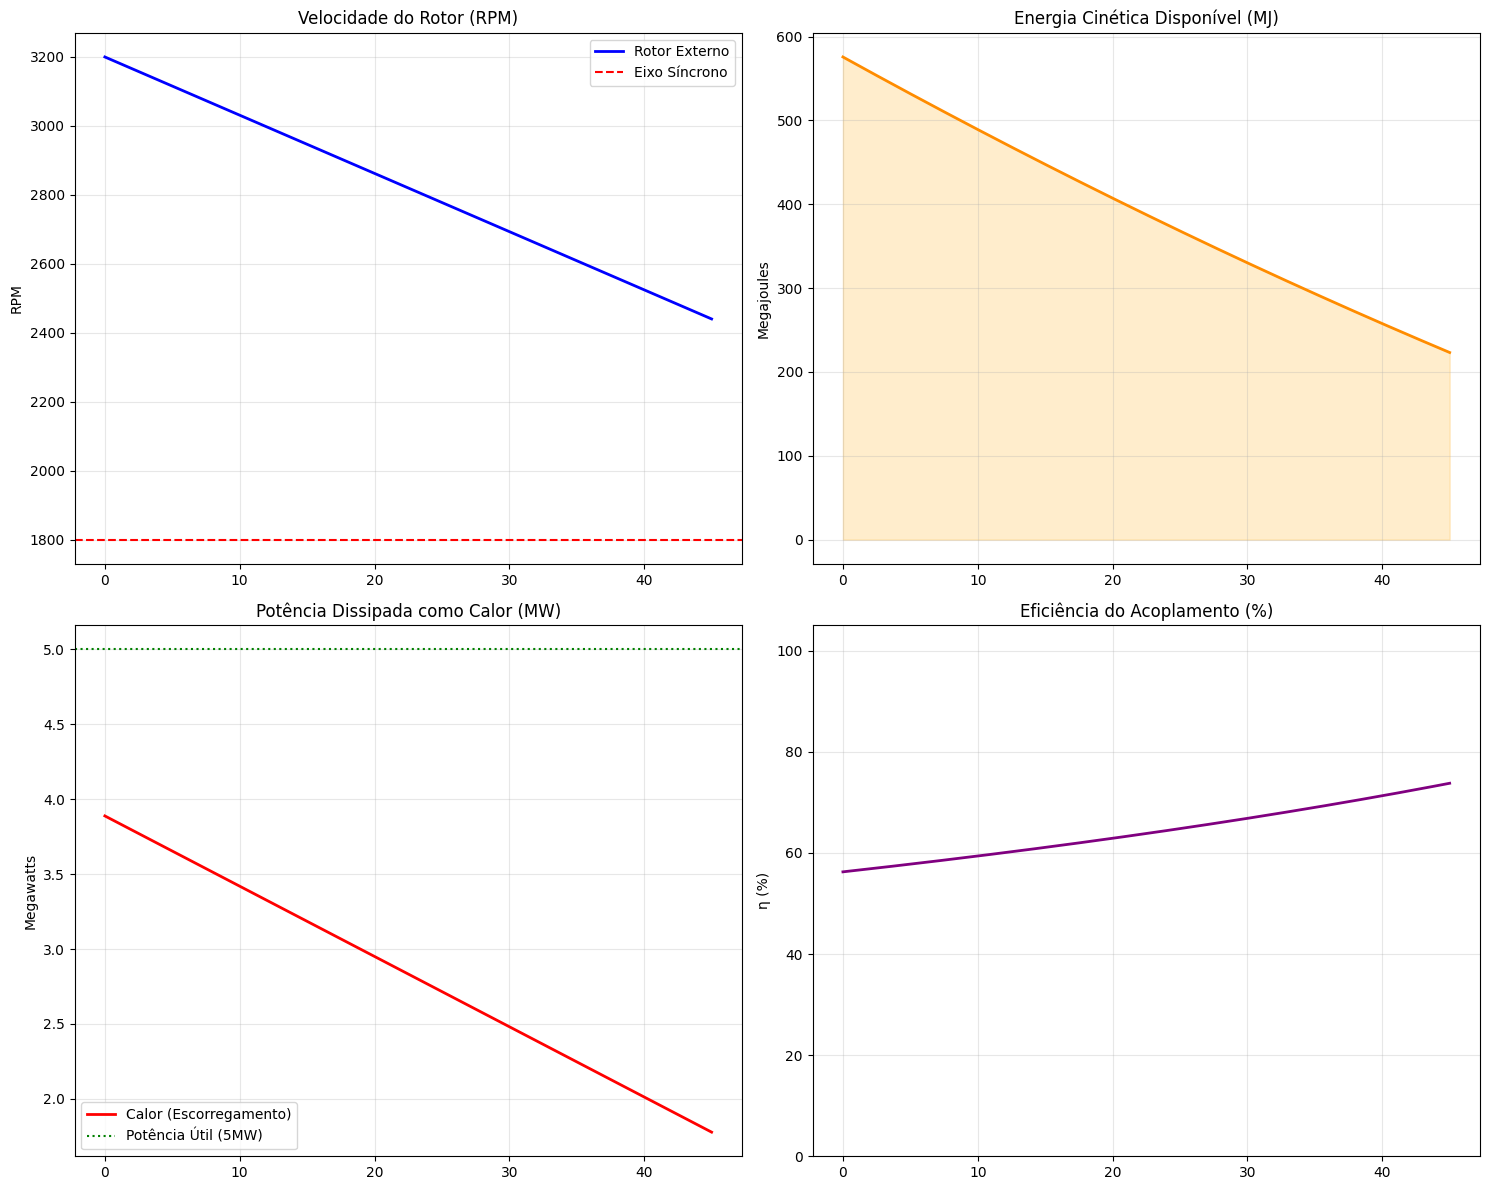

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(15, 12))

# 1. Velocidade
axs[0, 0].plot(t_sim, omega_r_sim * 60 / (2*np.pi), label='Rotor Externo', color='blue', lw=2)
axs[0, 0].axhline(y=1800, color='red', linestyle='--', label='Eixo Síncrono')
axs[0, 0].set_title("Velocidade do Rotor (RPM)")
axs[0, 0].set_ylabel("RPM")
axs[0, 0].legend()
axs[0, 0].grid(True, alpha=0.3)

# 2. Energia Disponível
axs[0, 1].fill_between(t_sim, energy_avail / 1e6, color='orange', alpha=0.2)
axs[0, 1].plot(t_sim, energy_avail / 1e6, color='darkorange', lw=2)
axs[0, 1].set_title("Energia Cinética Disponível (MJ)")
axs[0, 1].set_ylabel("Megajoules")
axs[0, 1].grid(True, alpha=0.3)

# 3. Potência Dissipada (Calor)
axs[1, 0].plot(t_sim, p_heat / 1e6, color='red', lw=2, label='Calor (Escorregamento)')
axs[1, 0].axhline(y=5, color='green', linestyle=':', label='Potência Útil (5MW)')
axs[1, 0].set_title("Potência Dissipada como Calor (MW)")
axs[1, 0].set_ylabel("Megawatts")
axs[1, 0].legend()
axs[1, 0].grid(True, alpha=0.3)

# 4. Eficiência
axs[1, 1].plot(t_sim, efficiency, color='purple', lw=2)
axs[1, 1].set_title("Eficiência do Acoplamento (%)")
axs[1, 1].set_ylabel("η (%)")
axs[1, 1].set_ylim(0, 105)
axs[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Conclusões de Engenharia

1.  **Autonomia:** O sistema sustenta 5 MW por aproximadamente 40 segundos antes de atingir o sincronismo.
2.  **Calor:** A dissipação inicial de **3.9 MW** exige um projeto térmico robusto para o rotor externo.
3.  **Viabilidade:** Em 400V, a corrente de ~9000A (considerando perdas e FP) sugere o uso de múltiplos cabos por fase ou barramentos pesados.